-   三点滑动平均的用途是，在重建输出图后、显示/算指标之前。是未来做超声成像恢复重建时，处理输出图的一个基本操作
-   三点滑动平均=用当前点和左右邻居共3个点的平均值取代替当前点的值。是低通滤波，能压掉高频噪声。

In [1]:
import numpy as np

x = np.array([1, 3, 2, 4, 1])

y_valid = np.convolve(x, np.ones(3) / 3, mode="valid")  # 约定A：只算完整窗 → 变短
y_same  = np.convolve(x, np.ones(3) / 3, mode="same")   # 约定B：补零 → 等长

print("原始 x      :", x)
print("valid (变短) :", y_valid)
print("same  (等长) :", y_same)


原始 x      : [1 3 2 4 1]
valid (变短) : [2.         3.         2.33333333]
same  (等长) : [1.33333333 2.         3.         2.33333333 1.66666667]


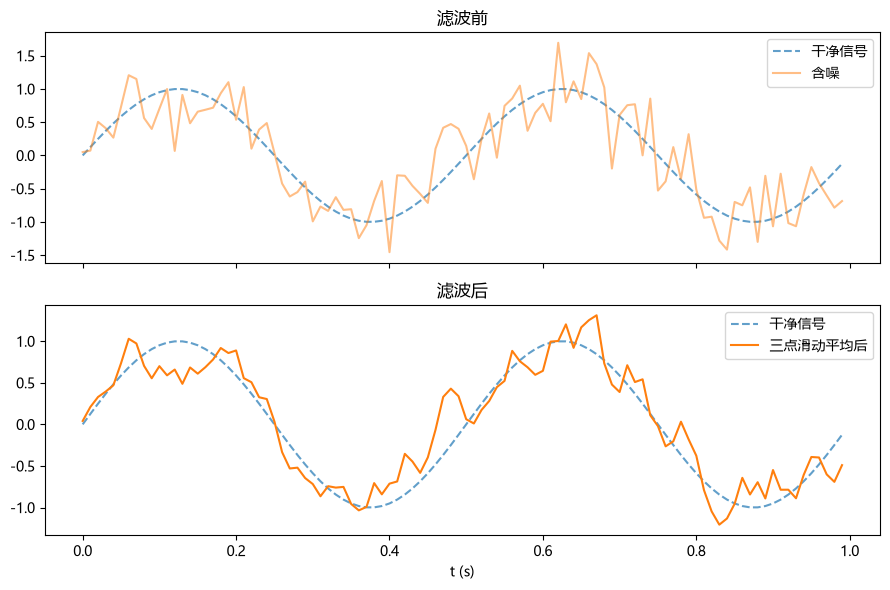

In [3]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

fs = 100
t = np.linspace(0, 1, fs, endpoint=False)
sig = np.sin(2 * np.pi * 2 * t)                     # 2Hz 干净信号
noise = 0.4 * np.random.default_rng(0).standard_normal(fs)    # 高斯噪声（固定种子可复现）
xn = sig + noise                                    # 含噪信号
yn = np.convolve(xn, np.ones(3) / 3, mode="same")   # 三点滑动平均

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(t, sig, "--", label="干净信号", alpha=0.7)
axes[0].plot(t, xn, alpha=0.5, label="含噪")
axes[0].set_title("滤波前"); axes[0].legend()
axes[1].plot(t, sig, "--", label="干净信号", alpha=0.7)
axes[1].plot(t, yn, label="三点滑动平均后")
axes[1].set_title("滤波后"); axes[1].legend(); axes[1].set_xlabel("t (s)")
fig.tight_layout()
plt.show()


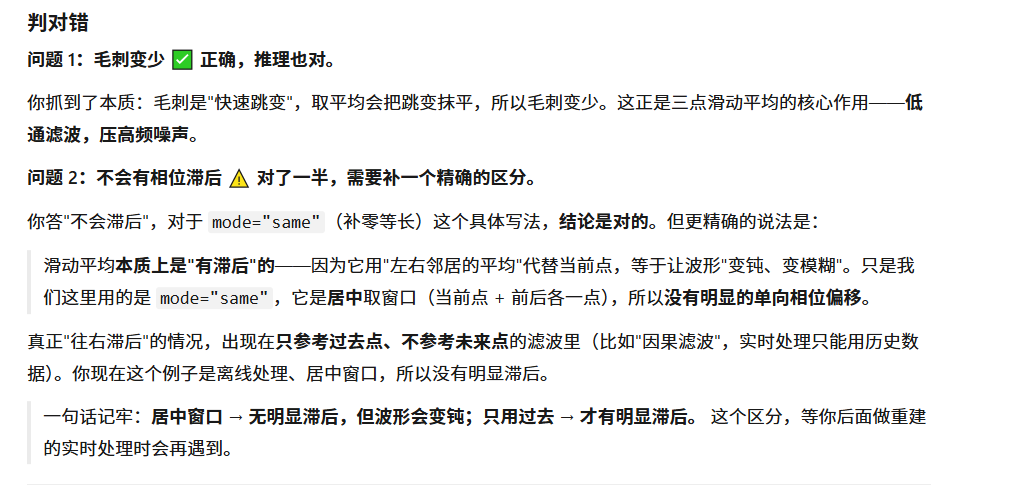